In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
with open("kidney_data.txt", "r") as file:
    f = file.readlines()
f

['"age" "tot"\n',
 '18 2.44\n',
 '19 3.86\n',
 '19 -1.22\n',
 '20 2.3\n',
 '21 0.98\n',
 '21 -0.5\n',
 '21 2.74\n',
 '22 -0.12\n',
 '22 -1.21\n',
 '22 0.99\n',
 '22 2.07\n',
 '22 1.55\n',
 '22 5.19\n',
 '23 -0.38\n',
 '23 1.62\n',
 '23 0.2\n',
 '23 0.15\n',
 '23 -1.28\n',
 '23 0.78\n',
 '23 2.94\n',
 '23 -2.12\n',
 '23 2.46\n',
 '23 4.63\n',
 '23 1.64\n',
 '24 -0.28\n',
 '24 0.67\n',
 '24 -0.43\n',
 '24 -2.1\n',
 '24 -0.82\n',
 '24 3.92\n',
 '24 1.63\n',
 '24 1.24\n',
 '24 -0.66\n',
 '24 0.15\n',
 '24 3.17\n',
 '24 -0.58\n',
 '25 2.69\n',
 '25 -0.24\n',
 '25 1.74\n',
 '25 5.07\n',
 '25 -3.3\n',
 '25 1.51\n',
 '25 3.93\n',
 '25 -0.87\n',
 '25 0.38\n',
 '25 -0.47\n',
 '26 2.33\n',
 '26 -0.05\n',
 '26 -1.1\n',
 '26 2.07\n',
 '26 -1.35\n',
 '26 -2.45\n',
 '26 -1.39\n',
 '27 0.59\n',
 '27 1.79\n',
 '27 1.27\n',
 '27 0.41\n',
 '27 -1.57\n',
 '27 0.83\n',
 '27 1.76\n',
 '27 -1.44\n',
 '27 2.55\n',
 '27 1.81\n',
 '27 2.82\n',
 '27 1.37\n',
 '28 -1.37\n',
 '28 1.27\n',
 '28 1.22\n',
 '28 -0.05\

In [3]:
kidney_dict = dict()
for i, line in enumerate(f):
    if i == 0:
        asd = line.strip().split(" ")
        age = asd[0].replace('"', '')
        tot = asd[1].replace('"', '')
        print(tot)
        kidney_dict[age] = []
        kidney_dict[tot] = []
        continue
    line = line.strip().split(" ")
    kidney_dict[age].append(line[0])
    kidney_dict[tot].append(line[1])


tot


In [4]:
df = pd.DataFrame(kidney_dict)

In [5]:
df.columns

Index(['age', 'tot'], dtype='object')

In [6]:
df["age"] = df["age"].astype(float)
df["tot"] = df["tot"].astype(float)


### Linear Regression

In [7]:
y = df["tot"].values
age = df["age"].values

X = np.column_stack([np.ones(len(age)), age])
X

array([[ 1., 18.],
       [ 1., 19.],
       [ 1., 19.],
       [ 1., 20.],
       [ 1., 21.],
       [ 1., 21.],
       [ 1., 21.],
       [ 1., 22.],
       [ 1., 22.],
       [ 1., 22.],
       [ 1., 22.],
       [ 1., 22.],
       [ 1., 22.],
       [ 1., 23.],
       [ 1., 23.],
       [ 1., 23.],
       [ 1., 23.],
       [ 1., 23.],
       [ 1., 23.],
       [ 1., 23.],
       [ 1., 23.],
       [ 1., 23.],
       [ 1., 23.],
       [ 1., 23.],
       [ 1., 24.],
       [ 1., 24.],
       [ 1., 24.],
       [ 1., 24.],
       [ 1., 24.],
       [ 1., 24.],
       [ 1., 24.],
       [ 1., 24.],
       [ 1., 24.],
       [ 1., 24.],
       [ 1., 24.],
       [ 1., 24.],
       [ 1., 25.],
       [ 1., 25.],
       [ 1., 25.],
       [ 1., 25.],
       [ 1., 25.],
       [ 1., 25.],
       [ 1., 25.],
       [ 1., 25.],
       [ 1., 25.],
       [ 1., 25.],
       [ 1., 26.],
       [ 1., 26.],
       [ 1., 26.],
       [ 1., 26.],
       [ 1., 26.],
       [ 1., 26.],
       [ 1.,

In [8]:
XtX = X.T @ X
XtX_inv = np.linalg.inv(XtX)
XtY = X.T @ y

beta_hat = XtX_inv @ XtY

In [9]:
beta_hat

array([ 2.8600268 , -0.07858842])

In [10]:
beta_0 = beta_hat[0]
beta_1 = beta_hat[1]

In [11]:
y_hat = beta_0 + beta_1 * df["age"].values

In [12]:
y_hat[0:10]

array([1.44543532, 1.3668469 , 1.3668469 , 1.28825848, 1.20967007,
       1.20967007, 1.20967007, 1.13108165, 1.13108165, 1.13108165])

In [ ]:
# setting up grid
age_grid =  np.linspace(0, age.max(), 100)
tot_hat_grid = beta_0 + beta_1 * age_grid

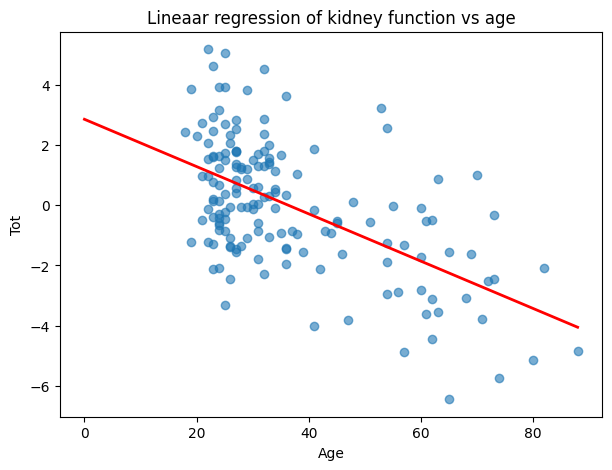

In [20]:
# plotting
plt.figure(figsize=(7,5))

# scatter plot
plt.scatter(age, y, alpha=0.6, label="Observed data")

# regression line
plt.plot(age_grid, tot_hat_grid, linewidth = 2, color="red", label="Linear fit")
plt.xlabel("Age")
plt.ylabel("Tot")
plt.title("Lineaar regression of kidney function vs age")
# plt.legend()
plt.show()

### Cubic Regression

In [21]:
age = df["age"].values
y   = df["tot"].values

In [22]:
X = np.column_stack([
    np.ones(len(age)),   # intercept
    age,                 # x
    age**2,              # x^2
    age**3               # x^3
])

In [23]:
XtX     = X.T @ X
XtX_inv = np.linalg.inv(XtX)
XtY     = X.T @ y

beta_hat = XtX_inv @ XtY
beta_hat

array([ 2.74055189e+00, -7.58906572e-02,  1.01582629e-04, -1.71976594e-06])

In [24]:
beta_0, beta_1, beta_2, beta_3 = beta_hat

In [25]:
y_hat = X @ beta_hat
residuals = y - y_hat

In [26]:
age_grid = np.linspace(age.min(), age.max(), 200)

X_grid = np.column_stack([
    np.ones(len(age_grid)),
    age_grid,
    age_grid**2,
    age_grid**3
])

y_grid = X_grid @ beta_hat

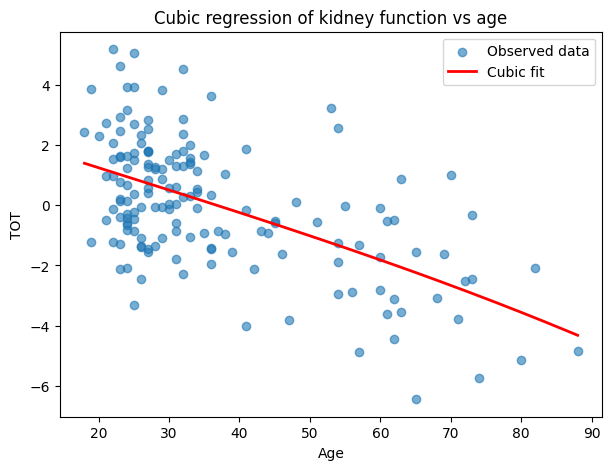

In [27]:
plt.figure(figsize=(7, 5))

plt.scatter(age, y, alpha=0.6, label="Observed data")
plt.plot(age_grid, y_grid, color="red", linewidth=2, label="Cubic fit")

plt.xlabel("Age")
plt.ylabel("TOT")
plt.title("Cubic regression of kidney function vs age")
plt.legend()
plt.show()

In [28]:
n = len(y)
p = X.shape[1]

sigma2_hat = (residuals @ residuals) / (n - p)

In [37]:
cov_beta = sigma2_hat * XtX_inv
se_beta  = np.sqrt(np.diag(cov_beta))

In [40]:
x0 = np.array([1, 20, 20**2, 20**3])  # [1, 20, 400, 8000]
y20_hat = x0 @ beta_hat

In [41]:
var_y20 = x0 @ cov_beta @ x0
se_y20 = np.sqrt(var_y20)

In [42]:
se_y20

np.float64(0.371693472352598)